In [ ]:
# Install the libraries used in this notebook
%pip install -q langchain langchain_core langgraph langchain_openai python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os

# Colab: read the key from Secrets. Elsewhere: read it from the .env file
try:
    from google.colab import userdata
    os.environ["OPENROUTER_API_KEY"] = userdata.get("OPENROUTER_API_KEY")
except ImportError:
    import dotenv
    dotenv.load_dotenv(".env")

In [ ]:
from langchain_openai import ChatOpenAI

# The model used in every section
llm = ChatOpenAI(
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base=os.getenv("OPENROUTER_BASE_URL", "https://openrouter.ai/api/v1"),
    model_name="openai/gpt-4o-mini-2024-07-18",  # or any model on OpenRouter
    default_headers={
        "HTTP-Referer": os.getenv("APP_URL", "http://localhost"),
        "X-Title": os.getenv("APP_NAME", "hopscotch-exchange-desk"),
    },
)

In [ ]:
# Ask the plain model about one of our orders
llm.invoke("What size and price is Hopscotch order HS2291, and how many days ago was it delivered?").content

"I'm sorry, but I don't have access to external databases or real-time information, so I'm unable to retrieve specifics about the Hopscotch order HS2291, including its size, price, or delivery date. You may want to check your order confirmation email or the Hopscotch website/app for details regarding your order."

## 2. Making a Tool
A tool is a Python function with `@tool` on top. Its **name**, **typed inputs** and **docstring** together form its **schema**, which is all the model reads.

### 2.1 The Order Store
A small mock order store stands in for the real database.

In [ ]:
# Mock order store (illustrative)
ORDERS = {
    "HS2291": {"item": "Kurta set", "size": "4-5Y", "vendor_id": "V2", "price": 1499, "days_since_delivery": 4},
    "HS3107": {"item": "Denim jacket", "size": "6-7Y", "vendor_id": "V5", "price": 2299, "days_since_delivery": 6},
    "HS1840": {"item": "Party dress", "size": "3-4Y", "vendor_id": "V3", "price": 1899, "days_since_delivery": 14},
}

In [ ]:
from langchain_core.tools import tool

@tool
def get_order(order_id: str) -> dict:
    """Look up a Hopscotch order by its id (for example HS2291).
    Returns the item, size, vendor_id, price in INR and days since delivery."""
    # The body is ordinary Python: the model never sees it
    order_id = order_id.upper()
    if order_id not in ORDERS:
        return {"order_id": order_id, "error": "order not found"}

    result = ORDERS[order_id].copy()
    result["order_id"] = order_id
    return result

In [ ]:
# The schema: name, description (from the docstring) and arguments (from the type hints)
print(get_order.name)
print(get_order.description)
print(get_order.args)

get_order
Look up a Hopscotch order by its id (for example HS2291).
Returns the item, size, vendor_id, price in INR and days since delivery.
{'order_id': {'title': 'Order Id', 'type': 'string'}}


In [ ]:
get_order.invoke({"order_id": "HS229134565432"})

{'order_id': 'HS229134565432', 'error': 'order not found'}

In [ ]:
llm_with_tools = llm.bind_tools([get_order])

In [ ]:
ai_msg = llm_with_tools.invoke("What size and price is order HS2291?")

In [ ]:
ai_msg.content

''

In [ ]:
ai_msg.tool_calls

[{'name': 'get_order',
  'args': {'order_id': 'HS2291'},
  'id': 'call_vNZSPnnVKKWo3Ba5w3uq3icM',
  'type': 'tool_call'}]

In [ ]:
import operator
from typing import Annotated, TypedDict

# The state holds one list of messages; every node appends to it
class ChatState(TypedDict):
    messages: Annotated[list, operator.add]

In [ ]:
# Node: the model reads the conversation and either requests tools or answers
def assistant(state: ChatState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

# Routing: tool calls -> run them; a text answer -> the run is done
def needs_tool(state: ChatState):
    if state["messages"][-1].tool_calls:
        return "tools"
    return "done"

In [ ]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode

graph = StateGraph(ChatState)

graph.add_node("assistant", assistant)
graph.add_node("tools", ToolNode([get_order]))   # executes every tool call in the last message

graph.add_edge(START, "assistant")
graph.add_conditional_edges("assistant", needs_tool, {"tools": "tools", "done": END})
graph.add_edge("tools", "assistant")             # the loop back: results return to the assistant

workflow = graph.compile()

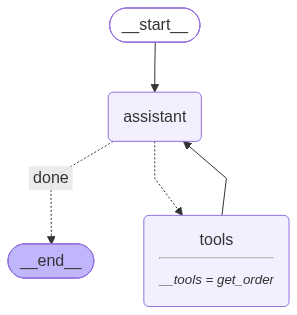

In [ ]:
# Draw the loop
from IPython.display import Image, display
display(Image(workflow.get_graph().draw_mermaid_png()))

In [ ]:
from langchain_core.messages import HumanMessage, ToolMessage

In [ ]:
final_state = workflow.invoke({"messages": [HumanMessage("What size and price is order HS2291?")]})

# Print every message in the state, in the order the nodes added them
for m in final_state["messages"]:
    m.pretty_print()

================================ Human Message =================================

What size and price is order HS2291?
================================== Ai Message ==================================
Tool Calls:
  get_order (call_81FgnKbX34CmiWFPuyYyB3OZ)
 Call ID: call_81FgnKbX34CmiWFPuyYyB3OZ
  Args:
    order_id: HS2291
================================= Tool Message =================================
Name: get_order

{"item": "Kurta set", "size": "4-5Y", "vendor_id": "V2", "price": 1499, "days_since_delivery": 4, "order_id": "HS2291"}
================================== Ai Message ==================================

Order HS2291 is a Kurta set in size 4-5Y, priced at ₹1499.
